# Taller: Redes neuronales con scikit-learn

### Regresión desde un enfoque de "caja negra"

**Curso:** Minería de Datos

---

## ¿Qué vamos a aprender?

Al terminar este taller vas a poder:

1. Entrenar una **red neuronal** (perceptrón multicapa) para **regresión** y para **clasificación** con `scikit-learn`.
2. Preparar los datos correctamente para que la red funcione (¡esto es más importante de lo que parece!).
3. **Analizar resultados**: métricas, gráficos, errores, variabilidad y qué variables importan.
4. **Ajustar hiperparámetros** con validación cruzada (`GridSearchCV` y `RandomizedSearchCV`).
5. Aplicar todo lo anterior por tu cuenta en dos problemas nuevos.

## Cómo trabajar con este notebook

- Ejecutá las celdas **en orden** (`Shift + Enter`). Muchas dependen de las anteriores.
- Los bloques con 🤔 **Para pensar** son preguntas para que discutas con tus colegas antes de seguir.
- Al final hay **actividades** para resolver solos/as reutilizando lo que vimos.
- Este notebook está pensado para **Google Colab**: guardá tu propia copia con `Archivo --> Guardar una copia en Drive`.
- No pasa nada si algo falla: ¡equivocarse es parte del proceso! Podés volver a ejecutar cualquier celda.

## Contenido

| Parte | Tema |
|---|---|
| 0 | La idea general: ¿qué es una red neuronal (MLP)? |
| 1 | Preparación del entorno |
| 2 | **Regresión**: predecir el consumo de combustible de autos |
| 3 | **Clasificación**: identificar especies de pingüinos |
| 4 | Resumen y buenas prácticas |
| 5 | **Actividades** para resolver por tu cuenta |

---
# Parte 0 · La idea general

## ¿Qué es un perceptrón multicapa (MLP)?

Un **MLP** (*Multi-Layer Perceptron*) es una red neuronal formada por capas de "neuronas" conectadas entre sí:

```
 Variables de           Capas ocultas            Salida
  entrada          (aquí "ocurre la magia")
                                                   
   x1 ──┐          ┌─ ○ ─┐      ┌─ ○ ─┐
   x2 ──┼────────► │  ○  │ ───► │  ○  │ ───────►  predicción
   x3 ──┤          │  ○  │      └─ ○ ─┘
   ...  ┘          └─ ○ ─┘
```

Cada neurona hace algo muy simple: **combina las entradas con unos pesos, suma y aplica una función de activación** (por ejemplo, ReLU). Al apilar muchas neuronas y varias capas, la red puede aprender relaciones **no lineales** complejas.

El entrenamiento consiste en **ajustar los pesos** para que las predicciones se parezcan cada vez más a los valores reales. Esto se hace de forma iterativa (descenso de gradiente): en cada *época* la red ve los datos, mide su error y corrige un poquito los pesos.

## El enfoque "caja negra"

En este taller **no vamos a programar la red ni a derivar ecuaciones**. Vamos a tratarla como una **caja negra configurable**:

- 1) 📥 Le damos datos (bien preparados).
- 2) 🎛️ Ajustamos unos "botones" (**hiperparámetros**).
- 3) 📊 Evaluamos qué tan bien predice y qué variables influyen.

> Esto **no** significa usarla a ciegas: significa saber **qué botones existen, qué hacen y cómo verificar que el resultado es confiable**.

## 🎛️ Los "botones" principales de `MLPRegressor` / `MLPClassifier`

| Hiperparámetro | ¿Qué controla? | Valores típicos |
|---|---|---|
| `hidden_layer_sizes` | Arquitectura: cuántas capas ocultas y cuántas neuronas en cada una. `(64, 32)` = 2 capas, de 64 y 32 neuronas | `(16,)`, `(64,)`, `(64, 32)` |
| `activation` | Función de activación de las capas ocultas | `"relu"`, `"tanh"`, `"logistic"` |
| `solver` | Algoritmo de optimización | `"adam"` (por defecto), `"lbfgs"` (bueno en datasets chicos), `"sgd"` |
| `alpha` | **Regularización** (penaliza pesos grandes → evita sobreajuste) | `0.0001` a `1` |
| `learning_rate_init` | Tamaño de los "pasos" de aprendizaje (solvers `adam`/`sgd`) | `0.0001` a `0.1` |
| `max_iter` | Máximo de épocas de entrenamiento | `500`, `1000`, `2000` |
| `early_stopping` | Corta el entrenamiento cuando deja de mejorar en validación | `True` / `False` |
| `random_state` | Semilla aleatoria (los pesos iniciales son aleatorios) | cualquier entero |

---
# Parte 1 · Preparación del entorno

Importamos las librerías que vamos a usar. En Google Colab ya vienen instaladas, no hace falta instalar nada.

In [ ]:
# ── Librerías básicas de datos y gráficos ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

# ── Utilidades de scikit-learn para preparar datos y validar ──
from sklearn.model_selection import (
    train_test_split, cross_val_score, validation_curve,
    GridSearchCV, RandomizedSearchCV, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

# ── Los modelos protagonistas: redes neuronales ──
from sklearn.neural_network import MLPRegressor, MLPClassifier

# ── Modelos de referencia (para comparar) ──
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression

# ── Métricas ──
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
)

# ── Para interpretar un modelo "caja negra" ──
from sklearn.inspection import permutation_importance

# ── Distribución para la búsqueda aleatoria de hiperparámetros ──
from scipy.stats import loguniform

# ── Configuración general ──
SEMILLA = 42                       # Fijamos la semilla para que los resultados sean reproducibles
sns.set_theme(style="whitegrid")   # Estilo de gráficos
pd.set_option("display.precision", 3)

# Las redes neuronales lanzan muchos avisos de "convergencia" cuando entrenamos decenas de modelos
# (por ejemplo, en las búsquedas de hiperparámetros). Para no llenar la pantalla los ocultamos,
# pero en la sección 7.1 los vamos a reactivar a propósito para entender qué significan.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
os.environ["PYTHONWARNINGS"] = "ignore::sklearn.exceptions.ConvergenceWarning"  # también en procesos paralelos

print("¡Todo listo!")

¡Todo listo!


---
# Parte 2 · Regresión con `MLPRegressor`

## El problema: ¿cuánto consume un auto?

Usaremos el dataset público **Auto MPG** (originalmente del repositorio UCI Machine Learning Repository), disponible en el repositorio de datos de ejemplo de `seaborn`.

Cada fila es un modelo de auto de los años 70-80. Queremos **predecir `mpg`** (millas por galón: a mayor `mpg`, menor consumo) a partir de las características del auto.

> **Variable objetivo (numérica continua):** `mpg` → esto es un problema de **regresión**.

In [ ]:
# Cargamos el dataset directamente desde un repositorio público en GitHub
url_mpg = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df_autos = pd.read_csv(url_mpg)

# Miramos las primeras filas
df_autos.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [ ]:
# Información general: tipos de datos y valores no nulos
df_autos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [ ]:
# Estadísticos descriptivos de las variables numéricas
df_autos.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000,398.000,398.000,392.000,398.000,398.000,398.000
mean,23.515,5.455,193.426,104.469,2970.425,15.568,76.010
std,7.816,1.701,104.270,38.491,846.842,2.758,3.698
min,9.000,3.000,68.000,46.000,1613.000,8.000,70.000
25%,17.500,4.000,104.250,75.000,2223.750,13.825,73.000
50%,23.000,4.000,148.500,93.500,2803.500,15.500,76.000
75%,29.000,8.000,262.000,126.000,3608.000,17.175,79.000
max,46.600,8.000,455.000,230.000,5140.000,24.800,82.000


In [ ]:
# ¿Hay valores faltantes?
print("Valores faltantes por columna:")
print(df_autos.isna().sum())

Valores faltantes por columna:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


Vemos que `horsepower` tiene **6 valores faltantes**. Las redes neuronales de `scikit-learn` **no aceptan valores faltantes**, así que más adelante los vamos a imputar (rellenar) dentro del propio flujo de trabajo.

Miremos algunos gráficos para entender los datos:

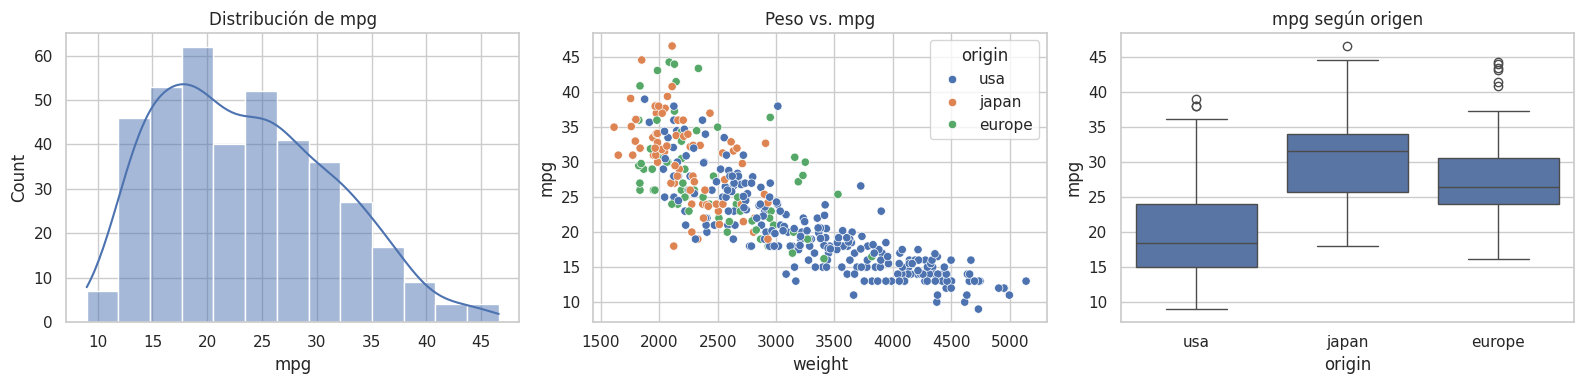

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))

# 1) Distribución de la variable objetivo
sns.histplot(df_autos["mpg"], kde=True, ax=ejes[0])
ejes[0].set_title("Distribución de mpg")

# 2) Relación entre peso y consumo
sns.scatterplot(data=df_autos, x="weight", y="mpg", hue="origin", ax=ejes[1])
ejes[1].set_title("Peso vs. mpg")

# 3) mpg según origen del auto
sns.boxplot(data=df_autos, x="origin", y="mpg", ax=ejes[2])
ejes[2].set_title("mpg según origen")

plt.tight_layout()
plt.show()

### 🤔 Para pensar
- ¿Qué relación observás entre el peso del auto y su consumo? ¿Parece lineal?
- ¿Crees que el origen del auto aporta información útil?


-Peso y consumo: hay una relación negativa clara. a mayor peso, menor mpg (es decir, mayor consumo). No parece perfectamente lineal: la caída es más fuerte en los autos livianos y se aplana en los pesados, por lo que la nube de puntos se curva en lugar de seguir una recta. Esto sugiere que un modelo no lineal, como una red neuronal, podría ajustarse mejor que una recta.

-Origen del auto: las medianas de mpg son distintas entre usa (≈ 18), europe (≈ 26) y japan (≈ 31). Sin embargo, los autos de usa tienden a ser más pesados, por lo que parte de esa diferencia puede deberse al peso y no al origen en sí. Habría que comprobar si el origen aporta algo adicional una vez que se tiene en cuenta el peso.

## Paso 1: separar variables y dividir en entrenamiento / prueba

- **X**: variables predictoras (características del auto). Quitamos `name` porque es un identificador, no una característica útil.
- **y**: variable objetivo (`mpg`).

Dividimos en:
- **Entrenamiento (80 %)**: con estos datos la red aprende.
- **Prueba (20 %)**: los guardamos "bajo llave" para evaluar al final. ⚠️ **No se tocan** hasta la evaluación final: simulan datos nuevos que el modelo nunca vio.

In [ ]:
# Separamos predictoras (X) y objetivo (y)
X = df_autos.drop(columns=["mpg", "name"])
y = df_autos["mpg"]

# Dividimos en entrenamiento y prueba
X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)

print(f"Entrenamiento: {X_ent.shape[0]} autos")
print(f"Prueba:        {X_prueba.shape[0]} autos")

Entrenamiento: 318 autos
Prueba:        80 autos


## Paso 2. Modelos de referencia (*baselines*)

Antes de entrenar una red neuronal, siempre conviene tener **modelos simples para comparar**. Si la red no le gana a un modelo simple, no vale la pena la complejidad.

Vamos a usar dos:
- **Dummy**: predice siempre el promedio de `mpg` (el modelo más "tonto" posible).
- **Regresión lineal**: un modelo simple y muy usado.

Primero definimos **cómo preparar los datos** (el "preprocesador") y una función para evaluar modelos.

### Preprocesamiento: ¡clave para las redes neuronales!

Las redes neuronales son **muy sensibles a la escala** de las variables. Por ejemplo, `weight` está en miles (≈ 3000) y `cylinders` entre 3 y 8. Si no las escalamos, la red aprende mal.

Necesitamos:
1. **Imputar** valores faltantes (con la mediana en variables numéricas).
2. **Estandarizar** las numéricas (`StandardScaler`: media 0 y desvío 1).
3. **Codificar** las categóricas como columnas 0/1 (`OneHotEncoder`), porque la red solo entiende números.

Todo esto lo empaquetamos en un `ColumnTransformer`. Lo bueno: al meterlo dentro de un `Pipeline`, el preprocesamiento se **ajusta solo con los datos de entrenamiento** y se aplica automáticamente a los de prueba (evitando "filtrar" información de prueba, lo que se llama *data leakage*).

In [ ]:
# Separamos las columnas según su tipo
cols_num = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
cols_cat = ["origin"]

# Preprocesador: qué hacerle a cada grupo de columnas
preprocesador_reg = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),   # rellena faltantes con la mediana
        ("escalar", StandardScaler())                    # media 0, desvío 1
    ]), cols_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cols_cat)  # categorías -> columnas 0/1
])

preprocesador_reg

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalar',
                                                  StandardScaler())]),
                                 ['cylinders', 'displacement', 'horsepower',
                                  'weight', 'acceleration', 'model_year']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['origin'])])

In [ ]:
# Función para evaluar un modelo de regresión de forma ordenada
def evaluar_regresion(modelo, X_ent, y_ent, X_prueba, y_prueba, nombre):
    pred_ent = modelo.predict(X_ent)
    pred_prueba = modelo.predict(X_prueba)
    return {
        "modelo": nombre,
        "RMSE_entrenamiento": root_mean_squared_error(y_ent, pred_ent),
        "RMSE_prueba": root_mean_squared_error(y_prueba, pred_prueba),
        "MAE_prueba": mean_absolute_error(y_prueba, pred_prueba),
        "R2_prueba": r2_score(y_prueba, pred_prueba),
    }

# Aquí iremos guardando los resultados de cada modelo para compararlos al final
resultados_reg = []

In [ ]:
# Baseline 1: predice siempre el promedio
modelo_dummy = DummyRegressor(strategy="mean")
modelo_dummy.fit(X_ent[cols_num], y_ent)
resultados_reg.append(evaluar_regresion(modelo_dummy, X_ent[cols_num], y_ent, X_prueba[cols_num], y_prueba, "Dummy (promedio)"))

# Baseline 2: regresión lineal (dentro de un Pipeline con el mismo preprocesador)
modelo_lineal = Pipeline([
    ("prep", preprocesador_reg),
    ("modelo", LinearRegression())
])
modelo_lineal.fit(X_ent, y_ent)
resultados_reg.append(evaluar_regresion(modelo_lineal, X_ent, y_ent, X_prueba, y_prueba, "Regresión lineal"))

pd.DataFrame(resultados_reg)

,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),7.918,7.347,5.955,-0.004
1,Regresión lineal,3.370,2.888,2.288,0.845


### 📏 ¿Cómo leer las métricas de regresión?

- **RMSE** (raíz del error cuadrático medio): error típico de la predicción, **en las mismas unidades que `mpg`**. Penaliza más los errores grandes. *Menor es mejor.*
- **MAE** (error absoluto medio): promedio de cuánto nos equivocamos, en unidades de `mpg`. *Menor es mejor.*
- **R²**: proporción de la variabilidad de `y` que el modelo explica. 1 = perfecto, 0 = igual que predecir el promedio. *Mayor es mejor.*

Fijate también en la diferencia entre **RMSE de entrenamiento y de prueba**: si en entrenamiento es mucho menor, hay señales de **sobreajuste** (el modelo "memorizó" en lugar de aprender).

## Paso 3 ¿Por qué hay que escalar? Una demostración

Veamos con nuestros propios ojos qué pasa si entrenamos la red **sin estandarizar** las variables (solo imputamos los faltantes) y lo comparamos con la red **con escalado**.

Como los pesos iniciales son aleatorios, repetimos el experimento con **5 semillas distintas** (una sola corrida podría engañarnos).

In [ ]:
r2_sin_escalar, r2_con_escalado = [], []

for semilla in range(5):
    # (a) Red SIN escalar: solo variables numéricas, imputadas
    sin_escalar = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=semilla))
    ]).fit(X_ent[cols_num], y_ent)
    r2_sin_escalar.append(r2_score(y_prueba, sin_escalar.predict(X_prueba[cols_num])))

    # (b) Red CON escalado: usamos nuestro preprocesador completo
    con_escalado = Pipeline([
        ("prep", preprocesador_reg),
        ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=semilla))
    ]).fit(X_ent, y_ent)
    r2_con_escalado.append(r2_score(y_prueba, con_escalado.predict(X_prueba)))

demo_escalado = pd.DataFrame({
    "semilla": range(5),
    "R2 sin escalar": r2_sin_escalar,
    "R2 con escalado": r2_con_escalado
})
demo_escalado

,semilla,R2 sin escalar,R2 con escalado
0,0,-3.391,0.898
1,1,0.796,0.903
2,2,-1.308,0.905
3,3,0.891,0.912
4,4,-72.231,0.909


> 💡 **Lección:** sin escalar, la red puede **divergir** (R² muy negativo: ¡peor que predecir siempre el promedio!) o depender de la suerte de la semilla. Con variables estandarizadas, el entrenamiento es **estable** y los resultados son buenos y consistentes. Por eso el escalado es **obligatorio** en redes neuronales.

## Paso 4: nuestra primera red neuronal para regresión

Armamos un `Pipeline` con dos pasos:
1. `prep`: el preprocesador que definimos.
2. `mlp`: la red neuronal `MLPRegressor`.

Usamos `hidden_layer_sizes=(64, 32)`: dos capas ocultas, la primera con 64 neuronas y la segunda con 32.

In [ ]:
# Definimos la red neuronal dentro de un Pipeline
mlp_reg = Pipeline([
    ("prep", preprocesador_reg),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(64, 32),   # 2 capas ocultas: 64 y 32 neuronas
        activation="relu",             # función de activación
        max_iter=2000,                 # máximo de épocas
        random_state=SEMILLA           # semilla para reproducibilidad
    ))
])

# Entrenamos ("fit") con los datos de entrenamiento
mlp_reg.fit(X_ent, y_ent)

# ¿Cuántas épocas usó realmente la red? (si es igual a max_iter, llegó al límite)
print("Épocas realizadas:", mlp_reg.named_steps["mlp"].n_iter_)

# Evaluamos y guardamos resultados
resultados_reg.append(evaluar_regresion(mlp_reg, X_ent, y_ent, X_prueba, y_prueba, "MLP inicial (64,32)"))
pd.DataFrame(resultados_reg)

Épocas realizadas: 2000


,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),7.918,7.347,5.955,-0.004
1,Regresión lineal,3.370,2.888,2.288,0.845
2,"MLP inicial (64,32)",1.745,2.427,1.763,0.890


## Paso 5 · Analizar los resultados

Los números solos no cuentan toda la historia. Miremos **tres gráficos** muy útiles:

1. **Curva de pérdida**: cómo baja el error durante el entrenamiento. Debería descender y estabilizarse.
2. **Real vs. predicho**: si el modelo fuera perfecto, todos los puntos estarían sobre la diagonal.
3. **Residuos** (real − predicho): deberían estar centrados en 0 y sin patrones marcados.

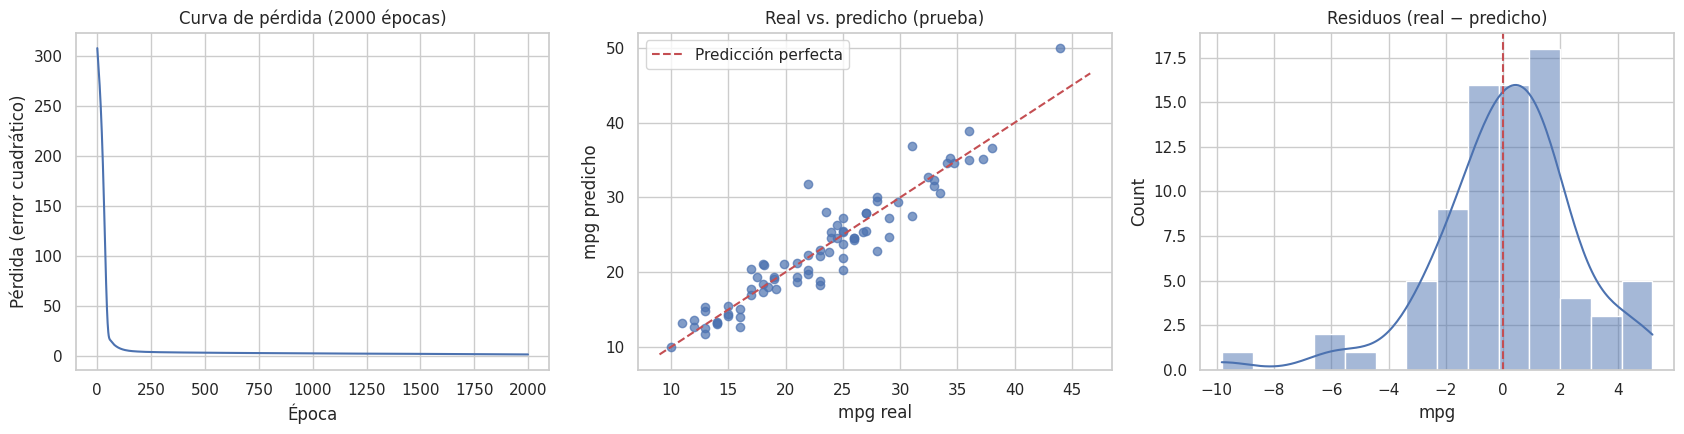

In [ ]:
# Obtenemos el objeto MLP que está dentro del Pipeline
red = mlp_reg.named_steps["mlp"]
pred_prueba = mlp_reg.predict(X_prueba)
residuos = y_prueba - pred_prueba

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) Curva de pérdida durante el entrenamiento
ejes[0].plot(red.loss_curve_)
ejes[0].set_title(f"Curva de pérdida ({red.n_iter_} épocas)")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Pérdida (error cuadrático)")

# 2) Real vs predicho
ejes[1].scatter(y_prueba, pred_prueba, alpha=0.7)
lim = [y.min(), y.max()]
ejes[1].plot(lim, lim, "r--", label="Predicción perfecta")
ejes[1].set_title("Real vs. predicho (prueba)")
ejes[1].set_xlabel("mpg real")
ejes[1].set_ylabel("mpg predicho")
ejes[1].legend()

# 3) Histograma de residuos
sns.histplot(residuos, kde=True, ax=ejes[2])
ejes[2].axvline(0, color="r", linestyle="--")
ejes[2].set_title("Residuos (real − predicho)")

plt.tight_layout()
plt.show()

### 🤔 Para pensar
- ¿La curva de pérdida se estabilizó, o el entrenamiento terminó "a la fuerza" por `max_iter`? (Mirá el número de épocas en el título del gráfico.)
- ¿En qué rango de `mpg` se equivoca más el modelo?


Curva de pérdida: el entrenamiento usó las 2000 épocas, es decir que terminó por el límite de max_iter y no por convergencia formal. Sin embargo, la curva baja muy rápido en las primeras ~50 épocas y después queda prácticamente plana, por lo que la red aprendió lo principal pronto y las épocas finales casi no aportan.

Rango donde más se equivoca: el modelo predice muy bien los autos de bajo mpg (entre 10 y 20), pero se equivoca más a partir de ≈ 22 mpg, donde hay más dispersión y los errores más grandes (por ejemplo, un auto de ≈ 22 mpg reales predicho en ≈ 32). Una posible explicación es que hay menos autos en ese rango, por lo que la red tiene menos ejemplos para aprender. Los residuos tienen forma de campana centrada cerca de 0, sin un sesgo claro, con unos pocos errores grandes.

## Paso 6 · Un detalle importante: la aleatoriedad

Los **pesos iniciales** de la red se eligen al azar. Eso significa que **dos entrenamientos con distinta semilla pueden dar resultados distintos**, aunque los datos y la configuración sean idénticos.

Veamos cuánto varía el resultado entrenando la misma red con 10 semillas diferentes:

R² en prueba con 10 semillas distintas:
[0.873 0.891 0.895 0.902 0.89  0.886 0.891 0.879 0.878 0.882]

Promedio: 0.887  |  Desvío: 0.008
Mínimo:   0.873  |  Máximo: 0.902


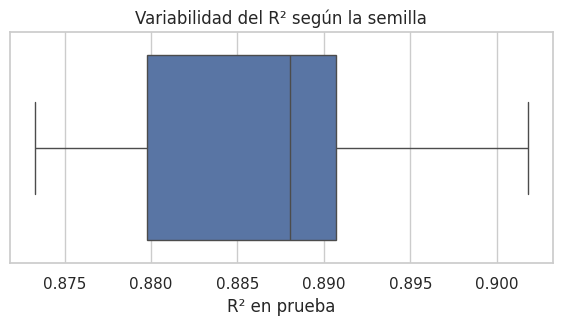

In [ ]:
r2_por_semilla = []

for semilla in range(10):
    modelo = clone(mlp_reg)                        # copia "limpia" del pipeline
    modelo.set_params(mlp__random_state=semilla)   # cambiamos solo la semilla de la red
    modelo.fit(X_ent, y_ent)
    r2_por_semilla.append(r2_score(y_prueba, modelo.predict(X_prueba)))

print("R² en prueba con 10 semillas distintas:")
print(np.round(r2_por_semilla, 3))
print(f"\nPromedio: {np.mean(r2_por_semilla):.3f}  |  Desvío: {np.std(r2_por_semilla):.3f}")
print(f"Mínimo:   {np.min(r2_por_semilla):.3f}  |  Máximo: {np.max(r2_por_semilla):.3f}")

plt.figure(figsize=(7, 3))
sns.boxplot(x=r2_por_semilla)
plt.title("Variabilidad del R² según la semilla")
plt.xlabel("R² en prueba")
plt.show()

> 💡 **Lección:** una diferencia pequeña entre dos configuraciones puede ser **puro azar**. Por eso es importante usar **validación cruzada** (que promedia varias evaluaciones) para comparar modelos, en lugar de fiarnos de una sola corrida.

## Paso 7 · Explorando hiperparámetros "a mano"

Antes de automatizar la búsqueda, entendamos el efecto de algunos "botones".

### 7.1 · `max_iter`: ¿y si cortamos el entrenamiento muy pronto?

Si la red no tiene tiempo suficiente para converger, `scikit-learn` nos avisa con un `ConvergenceWarning`:

In [ ]:
# Entrenamos con solo 20 épocas: ¡muy poco!
mlp_corto = clone(mlp_reg)
mlp_corto.set_params(mlp__max_iter=20)

# Reactivamos (solo dentro de este bloque) los avisos de convergencia que habíamos ocultado
with warnings.catch_warnings():
    warnings.simplefilter("always", ConvergenceWarning)
    mlp_corto.fit(X_ent, y_ent)   # <- verás una advertencia de convergencia

print(f"R² en prueba con 20 épocas:   {r2_score(y_prueba, mlp_corto.predict(X_prueba)):.3f}")
print(f"R² en prueba con 2000 épocas: {r2_score(y_prueba, mlp_reg.predict(X_prueba)):.3f}")

R² en prueba con 20 épocas:   -7.037
R² en prueba con 2000 épocas: 0.890


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


> ⚠️ **Si ves un `ConvergenceWarning`**: la red no terminó de aprender. Aumentá `max_iter`, o revisá que las variables estén escaladas.
>
> Al inicio del notebook ocultamos estos avisos para no llenar la pantalla, pero **no dejes de vigilar** cuántas épocas usa tu red: se consulta con `red.n_iter_` (si es igual a `max_iter`, el entrenamiento terminó por el límite y no porque convergió).

### 7.2 · `hidden_layer_sizes`: ¿cuántas neuronas necesitamos?

Usaremos una **curva de validación**: entrenamos redes de una capa con distinta cantidad de neuronas y medimos el R² tanto en entrenamiento como en validación cruzada (5 particiones del conjunto de entrenamiento).

- Pocas neuronas → el modelo es demasiado simple (**subajuste**).
- Muchas neuronas → puede volverse demasiado complejo (**sobreajuste**).

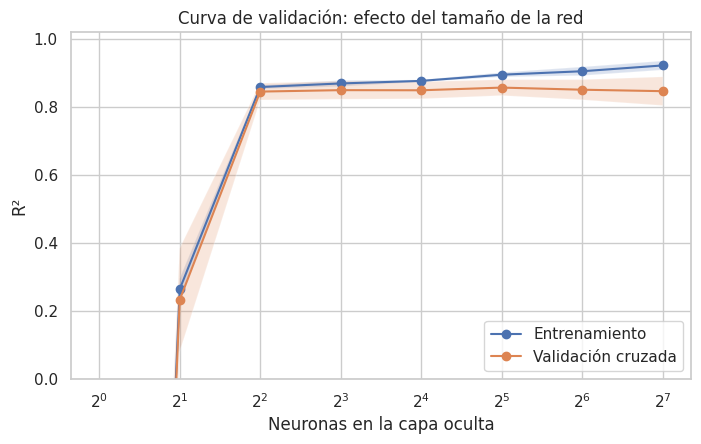

In [ ]:
# Probamos redes de una capa con distinta cantidad de neuronas
neuronas = [1, 2, 4, 8, 16, 32, 64, 128]
arquitecturas = [(n,) for n in neuronas]

puntaje_ent, puntaje_val = validation_curve(
    mlp_reg, X_ent, y_ent,
    param_name="mlp__hidden_layer_sizes",
    param_range=arquitecturas,
    cv=5, scoring="r2", n_jobs=-1
)

# Graficamos promedio ± desvío
plt.figure(figsize=(8, 4.5))
for puntajes, etiqueta in [(puntaje_ent, "Entrenamiento"), (puntaje_val, "Validación cruzada")]:
    media, desvio = puntajes.mean(axis=1), puntajes.std(axis=1)
    plt.plot(neuronas, media, marker="o", label=etiqueta)
    plt.fill_between(neuronas, media - desvio, media + desvio, alpha=0.2)

plt.xscale("log", base=2)
plt.xlabel("Neuronas en la capa oculta")
plt.ylabel("R²")
plt.title("Curva de validación: efecto del tamaño de la red")
plt.ylim(0, 1.02)
plt.legend()
plt.show()

### 🤔 Para pensar
- ¿A partir de cuántas neuronas deja de mejorar el R² de validación?
- ¿Hay una brecha entre la curva de entrenamiento y la de validación? ¿Qué nos dice eso?


-Con 1 y 2 neuronas el modelo es demasiado simple (R² muy bajo, subajuste). Con 4 neuronas el R² de validación salta a ≈ 0.85 y a partir de ahí se mantiene prácticamente plano (≈ 0.85 hasta 64 neuronas, y ≈ 0.845 con 128). O sea que desde las 4 neuronas agregar más no mejora la validación.

-Con pocas neuronas las dos curvas coinciden, pero a medida que la red crece el R² de entrenamiento sigue subiendo (≈ 0.92 con 128 neuronas) y el de validación no, lo que abre una brecha de ≈ 0.07-0.08. Esto indica sobreajuste: las redes más grandes memorizan mejor los datos de entrenamiento pero no generalizan mejor. Por eso, para este dataset, una red chica es suficiente.

## Paso 8: búsqueda automática de hiperparámetros: `GridSearchCV`

Probar combinaciones a mano es lento y poco riguroso. `GridSearchCV` hace esto por nosotros:

1. Definimos una **grilla** con los valores a probar para cada hiperparámetro.
2. Para **cada combinación**, entrena y evalúa con **validación cruzada** (aquí, 5 particiones).
3. Nos dice cuál fue la mejor y **reentrena** el mejor modelo con todo el conjunto de entrenamiento.

> ⚠️ Toda la búsqueda usa **solo los datos de entrenamiento**. El conjunto de prueba sigue intacto.

Nota: dentro de un `Pipeline`, los hiperparámetros se nombran como `paso__parametro` (con **doble guion bajo**), por ejemplo `mlp__alpha`.

Nuestra grilla tiene 3 × 3 × 2 = **18 combinaciones**, y con 5 particiones son 90 entrenamientos. Puede tardar 1-2 minutos. ☕

In [ ]:
# Grilla de hiperparámetros a explorar
grilla_reg = {
    "mlp__hidden_layer_sizes": [(16,), (64,), (64, 32)],   # arquitecturas
    "mlp__alpha": [0.0001, 0.01, 1.0],                     # regularización
    "mlp__learning_rate_init": [0.001, 0.01],              # tamaño de paso
}

busqueda_reg = GridSearchCV(
    estimator=mlp_reg,
    param_grid=grilla_reg,
    cv=5,                                     # validación cruzada de 5 particiones
    scoring="neg_root_mean_squared_error",    # sklearn maximiza: usamos -RMSE
    n_jobs=-1,                                # usa todos los núcleos disponibles
    verbose=1
)

busqueda_reg.fit(X_ent, y_ent)

print("\nMejores hiperparámetros:")
print(busqueda_reg.best_params_)
print(f"\nMejor RMSE en validación cruzada: {-busqueda_reg.best_score_:.3f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits

Mejores hiperparámetros:
{'mlp__alpha': 1.0, 'mlp__hidden_layer_sizes': (64,), 'mlp__learning_rate_init': 0.01}

Mejor RMSE en validación cruzada: 2.877


### Mirando todos los resultados de la búsqueda

`cv_results_` guarda lo que pasó con **cada** combinación. Conviene convertirlo en una tabla y ordenarlo. Prestá atención a la columna `std_test_score`: si el desvío es grande comparado con las diferencias entre modelos, esas diferencias **no son concluyentes**.

In [ ]:
res = pd.DataFrame(busqueda_reg.cv_results_)
res["RMSE_cv"] = -res["mean_test_score"]     # volvemos a un RMSE positivo

columnas = ["param_mlp__hidden_layer_sizes", "param_mlp__alpha", "param_mlp__learning_rate_init",
            "RMSE_cv", "std_test_score", "rank_test_score"]

res.sort_values("rank_test_score")[columnas].head(8)

,param_mlp__hidden_layer_sizes,param_mlp__alpha,param_mlp__learning_rate_init,RMSE_cv,std_test_score,rank_test_score
15,"(64,)",1.000e+00,0.010,2.877,0.330,1
16,"(64, 32)",1.000e+00,0.001,2.953,0.228,2
10,"(64, 32)",1.000e-02,0.001,2.973,0.267,3
4,"(64, 32)",1.000e-04,0.001,2.974,0.239,4
17,"(64, 32)",1.000e+00,0.010,2.982,0.335,5
14,"(64,)",1.000e+00,0.001,3.011,0.344,6
9,"(64,)",1.000e-02,0.010,3.013,0.257,7
12,"(16,)",1.000e+00,0.001,3.020,0.303,8


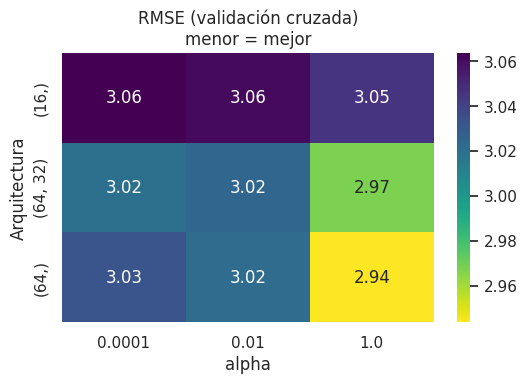

In [ ]:
# Visualizamos: RMSE promedio según arquitectura y alpha (promediando sobre learning rate)
res["arquitectura"] = res["param_mlp__hidden_layer_sizes"].astype(str)
tabla = res.pivot_table(index="arquitectura", columns="param_mlp__alpha", values="RMSE_cv", aggfunc="mean")

plt.figure(figsize=(6, 3.5))
sns.heatmap(tabla, annot=True, fmt=".2f", cmap="viridis_r")
plt.title("RMSE (validación cruzada)\nmenor = mejor")
plt.xlabel("alpha")
plt.ylabel("Arquitectura")
plt.show()

## Paso 9 · Evaluación final en el conjunto de prueba

Ahora sí, usamos por **única vez** el conjunto de prueba para evaluar el mejor modelo encontrado. Lo tenemos en `busqueda_reg.best_estimator_` (ya reentrenado con todo el conjunto de entrenamiento).

In [ ]:
mejor_reg = busqueda_reg.best_estimator_

resultados_reg.append(evaluar_regresion(mejor_reg, X_ent, y_ent, X_prueba, y_prueba, "MLP optimizado (GridSearch)"))

tabla_final_reg = pd.DataFrame(resultados_reg).set_index("modelo")
tabla_final_reg

,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
modelo,,,,
Dummy (promedio),7.918,7.347,5.955,-0.004
Regresión lineal,3.370,2.888,2.288,0.845
"MLP inicial (64,32)",1.745,2.427,1.763,0.890
MLP optimizado (GridSearch),2.176,2.404,1.796,0.893


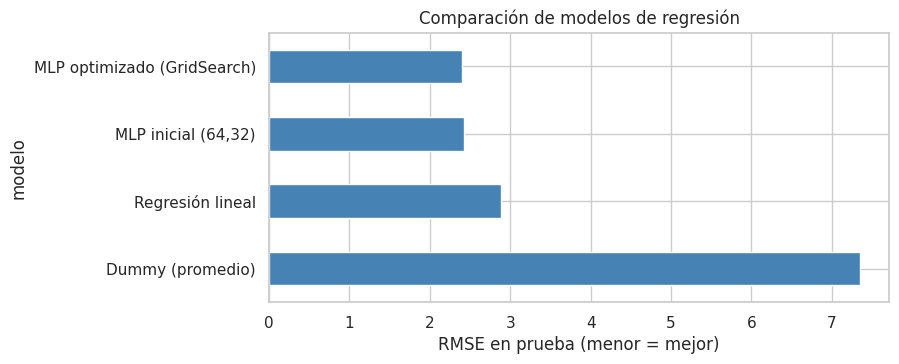

In [ ]:
# Comparamos gráficamente el RMSE en prueba de todos los modelos
tabla_final_reg["RMSE_prueba"].plot(kind="barh", figsize=(8, 3.5), color="steelblue")
plt.xlabel("RMSE en prueba (menor = mejor)")
plt.title("Comparación de modelos de regresión")
plt.show()

## Paso 10. Abriendo un poco la caja negra: importancia por permutación

Aunque la red es una "caja negra", podemos preguntarle **qué variables le importan**. La **importancia por permutación** funciona así:

1. Tomamos los datos de prueba y **mezclamos al azar** los valores de **una** variable.
2. Medimos cuánto **empeora** el error del modelo.
3. Si empeora mucho → esa variable era **importante**. Si casi no cambia → no aportaba.

Como usamos el `Pipeline` completo, la importancia se calcula sobre las **variables originales** (por ejemplo `origin` completo, no cada columna 0/1).

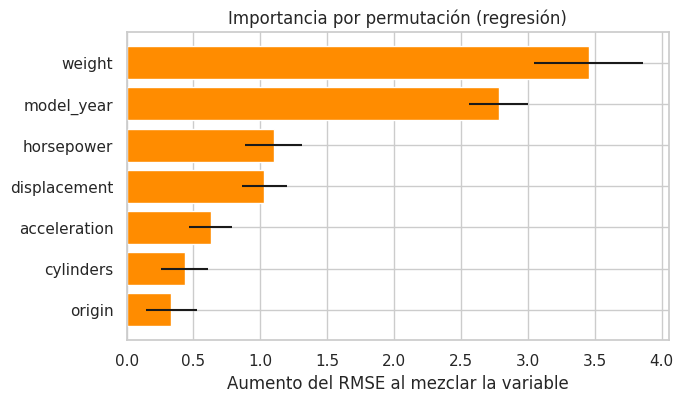

In [ ]:
imp = permutation_importance(
    mejor_reg, X_prueba, y_prueba,
    n_repeats=20,                              # repetimos el mezclado 20 veces
    scoring="neg_root_mean_squared_error",
    random_state=SEMILLA
)

importancias = pd.DataFrame({
    "variable": X_prueba.columns,
    "aumento_RMSE": imp.importances_mean,      # cuánto empeora el RMSE al mezclar la variable
    "desvio": imp.importances_std
}).sort_values("aumento_RMSE")

plt.figure(figsize=(7, 4))
plt.barh(importancias["variable"], importancias["aumento_RMSE"], xerr=importancias["desvio"], color="darkorange")
plt.xlabel("Aumento del RMSE al mezclar la variable")
plt.title("Importancia por permutación (regresión)")
plt.show()

### Usando el modelo en un caso nuevo

Una vez entrenado, el `Pipeline` funciona como una función: le pasamos un auto **con las columnas originales** y devuelve la predicción (el preprocesamiento se hace solo).

In [ ]:
# Un auto hipotético que no está en el dataset
auto_nuevo = pd.DataFrame([{
    "cylinders": 4, "displacement": 120, "horsepower": 95,
    "weight": 2300, "acceleration": 15, "model_year": 80, "origin": "japan"
}])

print(f"Consumo predicho: {mejor_reg.predict(auto_nuevo)[0]:.1f} mpg")

Consumo predicho: 30.6 mpg


---
# Parte 4. Resumen y buenas prácticas

## La receta que usamos (sirve para regresión y clasificación)

1. **Explorar** los datos (tipos, faltantes, distribuciones).
2. **Dividir** en entrenamiento y prueba (con `stratify` si es clasificación).
3. **Preprocesar dentro de un `Pipeline`**: imputar → escalar numéricas → codificar categóricas.
4. Entrenar **modelos de referencia** (Dummy, lineal/logístico) para tener con qué comparar.
5. Entrenar la **red neuronal** y **analizar resultados** (métricas, gráficos, errores).
6. **Ajustar hiperparámetros** con validación cruzada (`GridSearchCV` / `RandomizedSearchCV`), usando **solo** el conjunto de entrenamiento.
7. **Evaluar una sola vez** en el conjunto de prueba.
8. **Interpretar** con importancia por permutación y **reportar** con honestidad (¡incluida la variabilidad!).

## ✅ Checklist rápido

| Situación | Qué hacer |
|---|---|
| `ConvergenceWarning` (o `n_iter_` igual a `max_iter`) | Aumentar `max_iter`, verificar que las variables estén escaladas, probar otro `solver` |
| Rendimiento muy bueno en entrenamiento y malo en prueba (sobreajuste) | Aumentar `alpha`, reducir neuronas, usar `early_stopping=True`, conseguir más datos |
| Rendimiento malo en ambos (subajuste) | Más neuronas/capas, más épocas, mejores variables |
| Resultados que cambian mucho entre corridas | Fijar `random_state`, comparar con validación cruzada, repetir con varias semillas |
| Dataset muy pequeño | Probar `solver="lbfgs"` |
| Clases desbalanceadas | No confiar solo en accuracy: mirar F1 macro, recall por clase y matriz de confusión |

## ⚖️ Ventajas y limitaciones de los MLP

** Ventajas:** capturan relaciones no lineales e interacciones complejas sin que las especifiquemos.

**Limitaciones:** son sensibles a la escala, tienen muchos hiperparámetros, son poco interpretables y suelen no superar a otros métodos (como bosques aleatorios o *gradient boosting*) en datos tabulares pequeños. ¡Siempre comparalos!

> `scikit-learn` es ideal para aprender y para problemas tabulares pequeños o medianos. Para redes profundas, imágenes, texto o mucho volumen de datos se usan librerías como **PyTorch** o **TensorFlow/Keras**.

---
# Parte 5 - Actividades

Ahora es tu turno. **Reutilizá el código de las partes anteriores** (copiar, pegar y adaptar es totalmente válido). Cada actividad indica qué parte del taller te sirve de guía.

> 💡 En las celdas de código encontrarás pistas como comentarios. Las celdas de texto "**Tu respuesta:**" son para que escribas tus conclusiones (doble clic para editar).

## Actividad 1. Regresión: predecir el precio de diamantes

**Dataset:** `diamonds` (público, repositorio de datos de `seaborn`). Cada fila es un diamante con su precio en dólares y características como peso (`carat`), calidad de corte (`cut`), color (`color`), claridad (`clarity`) y dimensiones (`x`, `y`, `z`).

**Objetivo:** predecir `price` con una red neuronal y compararla con modelos de referencia.

**Te sirve de guía:** Parte 2 (Regresión).

Para que los entrenamientos no tarden demasiado, trabajaremos con una **muestra de 3000 diamantes**.

In [ ]:
# Cargamos el dataset y tomamos una muestra de 3000 filas
url_diamantes = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"
df_diam = pd.read_csv(url_diamantes).sample(n=3000, random_state=SEMILLA).reset_index(drop=True)

df_diam.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
1,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
2,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
3,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
4,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61


**1.1 · Exploración.** Averiguá: ¿cuántas variables numéricas y categóricas hay? ¿Hay valores faltantes? Graficá la distribución de `price` y la relación entre `carat` y `price`. ¿Notás algo particular en la distribución del precio?

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    3000 non-null   float64
 1   cut      3000 non-null   object 
 2   color    3000 non-null   object 
 3   clarity  3000 non-null   object 
 4   depth    3000 non-null   float64
 5   table    3000 non-null   float64
 6   price    3000 non-null   int64  
 7   x        3000 non-null   float64
 8   y        3000 non-null   float64
 9   z        3000 non-null   float64
dtypes: float64(6), int64(1), object(3)
memory usage: 234.5+ KB

Variables numéricas (7): ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
Variables categóricas (3): ['cut', 'color', 'clarity']

Valores faltantes por columna:
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64


,carat,depth,table,price,x,y,z
count,3000.000,3000.000,3000.000,3000.000,3000.000,3000.000,3000.000
mean,0.803,61.760,57.453,3946.290,5.735,5.735,3.541
std,0.490,1.432,2.288,4083.685,1.149,1.142,0.706
min,0.230,54.400,49.000,358.000,3.880,3.920,2.320
25%,0.390,61.075,56.000,926.750,4.680,4.690,2.890
50%,0.700,61.900,57.000,2352.000,5.690,5.700,3.520
75%,1.040,62.500,59.000,5303.250,6.560,6.560,4.030
max,4.010,69.900,73.000,18823.000,10.020,9.940,6.310



Filas con x, y o z igual a 0: 0


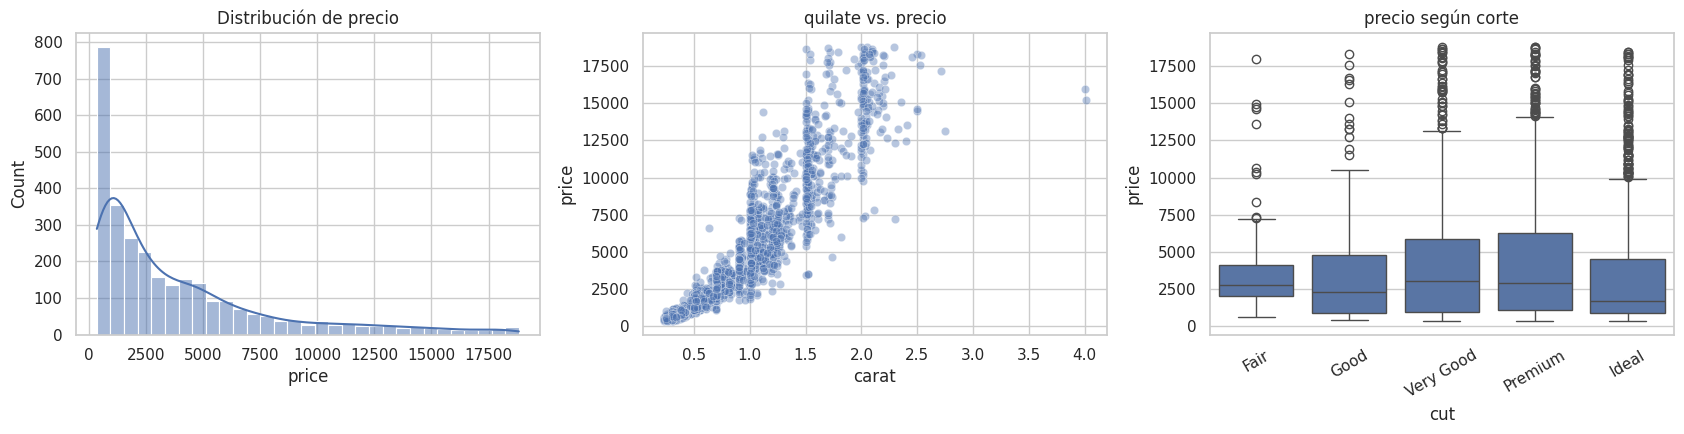

In [ ]:
# 1.1 · Exploración de df_diam

# Información general: tipos de datos y valores no nulos
df_diam.info()

# Cantidad de variables numéricas y categóricas
vars_num = df_diam.select_dtypes(include="number").columns.tolist()
vars_cat = df_diam.select_dtypes(exclude="number").columns.tolist()
print(f"\nVariables numéricas ({len(vars_num)}): {vars_num}")
print(f"Variables categóricas ({len(vars_cat)}): {vars_cat}")

# Valores faltantes
print("\nValores faltantes por columna:")
print(df_diam.isna().sum())

# Estadísticos descriptivos
display(df_diam.describe())

# Por si hay dimensiones imposibles (un diamante no puede medir 0 mm)
print("\nFilas con x, y o z igual a 0:", ((df_diam[["x", "y", "z"]] == 0).any(axis=1)).sum())

# Gráficos
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) Distribución del precio
sns.histplot(df_diam["price"], kde=True, ax=ejes[0])
ejes[0].set_title("Distribución de precio")

# 2) Relación entre quilates y precio
sns.scatterplot(data=df_diam, x="carat", y="price", alpha=0.4, ax=ejes[1])
ejes[1].set_title("quilate vs. precio")

# 3) Precio según calidad de corte
sns.boxplot(data=df_diam, x="cut", y="price",
            order=["Fair", "Good", "Very Good", "Premium", "Ideal"], ax=ejes[2])
ejes[2].set_title("precio según corte")
ejes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

**Tu respuesta (1.1):**

El dataset tiene 3000 diamantes, con 7 variables numéricas (carat, depth, table, price, x, y, z) y 3 categóricas (cut, color, clarity). No hay valores faltantes ni dimensiones iguales a 0, por lo que los datos están completos.

Distribución del precio: es muy asimétrica hacia la derecha: hay muchos diamantes baratos y pocos muy caros. Lo confirma que el promedio (≈ 3946 USD) sea bastante mayor que la mediana (≈ 2352 USD). Esto es algo particular porque una distribución con forma de campana sería más fácil de predecir, y acá los pocos valores muy altos pueden pesar mucho en el error.

Relación carat - price: a más quilates, mayor precio, pero la relación no es lineal: la nube de puntos se curva hacia arriba. Además la dispersión aumenta con el tamaño: para diamantes de 1.5 o 2 quilates hay precios muy distintos, así que el peso por sí solo no explica todo y otras variables (como clarity y color) también influyen.

En el boxplot por cut, los cortes Ideal tienen una mediana de precio menor que los demás, lo que parece contradictorio. Probablemente se deba a que los diamantes de mejor corte de esta muestra son en promedio más chicos, y el tamaño pesa más en el precio que el corte.

**1.2 · División y preprocesamiento.**
- Separá `X` (todo menos `price`) e `y` (`price`).
- Dividí en entrenamiento (80 %) y prueba (20 %).
- Armá un `ColumnTransformer` que estandarice las numéricas y aplique `OneHotEncoder` a `cut`, `color` y `clarity`.

In [ ]:
# 1.2 · División y preprocesamiento

# Separamos predictoras (X) y objetivo (y)
X_d = df_diam.drop(columns=["price"])
y_d = df_diam["price"]

# División 80 % entrenamiento / 20 % prueba
X_ent_d, X_prueba_d, y_ent_d, y_prueba_d = train_test_split(
    X_d, y_d, test_size=0.2, random_state=SEMILLA
)

print(f"Entrenamiento: {X_ent_d.shape[0]} diamantes")
print(f"Prueba:        {X_prueba_d.shape[0]} diamantes")

# Columnas según su tipo (price no está: es la variable objetivo)
cols_num_d = ["carat", "depth", "table", "x", "y", "z"]
cols_cat_d = ["cut", "color", "clarity"]

# Preprocesador: estandarizar numéricas y codificar categóricas en columnas 0/1
preprocesador_diam = ColumnTransformer([
    ("num", StandardScaler(), cols_num_d),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cols_cat_d)
])

preprocesador_diam

Entrenamiento: 2400 diamantes
Prueba:        600 diamantes


ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['carat', 'depth', 'table', 'x', 'y', 'z']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['cut', 'color', 'clarity'])])

**1.3 · Modelos de referencia.** Entrená un `DummyRegressor` y una `LinearRegression`, y guardá sus métricas (RMSE, MAE, R²) en una lista de resultados usando la función `evaluar_regresion` que ya definimos.

In [ ]:
# 1.3 · Modelos de referencia

# Aquí guardamos los resultados de cada modelo para compararlos después
resultados_diam = []

# Baseline 1: predice siempre el precio promedio
modelo_dummy_d = DummyRegressor(strategy="mean")
modelo_dummy_d.fit(X_ent_d[cols_num_d], y_ent_d)
resultados_diam.append(evaluar_regresion(
    modelo_dummy_d, X_ent_d[cols_num_d], y_ent_d,
    X_prueba_d[cols_num_d], y_prueba_d, "Dummy (promedio)"
))

# Baseline 2: regresión lineal (dentro de un Pipeline con el preprocesador de 1.2)
modelo_lineal_d = Pipeline([
    ("prep", preprocesador_diam),
    ("modelo", LinearRegression())
])
modelo_lineal_d.fit(X_ent_d, y_ent_d)
resultados_diam.append(evaluar_regresion(
    modelo_lineal_d, X_ent_d, y_ent_d,
    X_prueba_d, y_prueba_d, "Regresión lineal"
))

pd.DataFrame(resultados_diam)

,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),4040.451,4249.481,3220.319,-0.001
1,Regresión lineal,1138.336,1106.483,730.659,0.932


**1.4 · Primera red neuronal.** Entrená un `MLPRegressor` con `hidden_layer_sizes=(64, 32)` dentro de un `Pipeline`. Evaluá en entrenamiento y prueba. Graficá **real vs. predicho** y la **curva de pérdida**. ¿Le gana a la regresión lineal?

Épocas realizadas: 2000 de un máximo de 2000


,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),4040.451,4249.481,3220.319,-0.001
1,Regresión lineal,1138.336,1106.483,730.659,0.932
2,"MLP inicial (64,32)",587.467,595.227,333.803,0.980


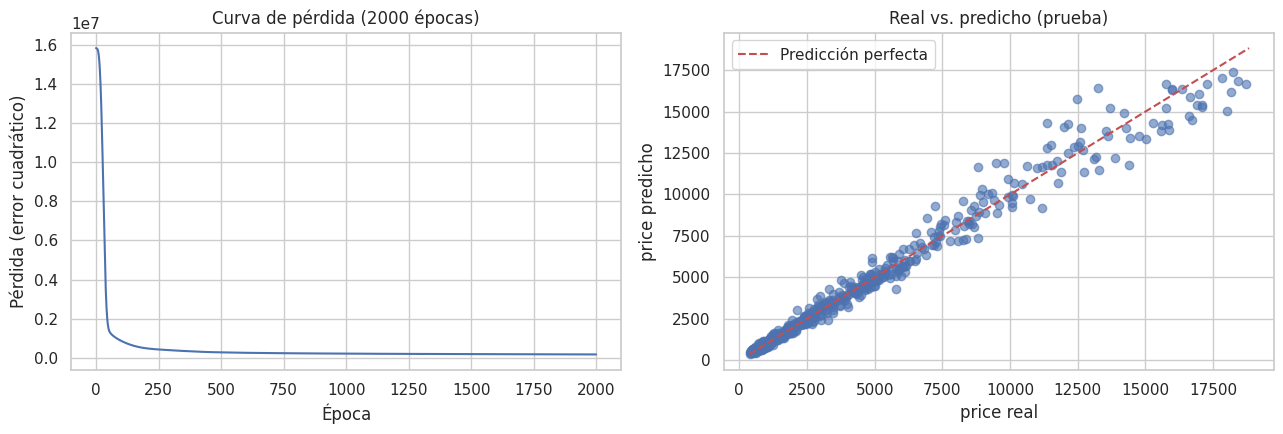

In [ ]:
# 1.4 · Primera red neuronal

# Pipeline: preprocesador de 1.2 + red neuronal
mlp_diam = Pipeline([
    ("prep", preprocesador_diam),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(64, 32),   # 2 capas ocultas: 64 y 32 neuronas
        activation="relu",
        max_iter=2000,
        random_state=SEMILLA
    ))
])

# Entrenamos con los datos de entrenamiento
mlp_diam.fit(X_ent_d, y_ent_d)

# ¿Cuántas épocas usó? (si es igual a max_iter, llegó al límite sin converger)
red_d = mlp_diam.named_steps["mlp"]
print("Épocas realizadas:", red_d.n_iter_, "de un máximo de", red_d.max_iter)

# Evaluamos (entrenamiento y prueba) y guardamos en la lista de resultados
resultados_diam.append(evaluar_regresion(
    mlp_diam, X_ent_d, y_ent_d, X_prueba_d, y_prueba_d, "MLP inicial (64,32)"
))
display(pd.DataFrame(resultados_diam))

# Gráficos: curva de pérdida y real vs. predicho
pred_prueba_d = mlp_diam.predict(X_prueba_d)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1) Curva de pérdida
ejes[0].plot(red_d.loss_curve_)
ejes[0].set_title(f"Curva de pérdida ({red_d.n_iter_} épocas)")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Pérdida (error cuadrático)")

# 2) Real vs. predicho
ejes[1].scatter(y_prueba_d, pred_prueba_d, alpha=0.6)
lim = [y_d.min(), y_d.max()]
ejes[1].plot(lim, lim, "r--", label="Predicción perfecta")
ejes[1].set_title("Real vs. predicho (prueba)")
ejes[1].set_xlabel("price real")
ejes[1].set_ylabel("price predicho")
ejes[1].legend()

plt.tight_layout()
plt.show()

**1.5 · Ajuste de hiperparámetros.** Usá `GridSearchCV` o `RandomizedSearchCV` (a tu elección) con validación cruzada de 5 particiones para explorar al menos **3 hiperparámetros** (por ejemplo `hidden_layer_sizes`, `alpha`, `learning_rate_init`). Mostrá los 5 mejores resultados y evaluá el mejor modelo en el conjunto de prueba.

⏱️ *Cuidado con el tiempo de ejecución: empezá con una grilla chica.*

In [ ]:
# 1.5 · Ajuste de hiperparámetros con GridSearchCV

# Grilla chica a propósito (2 x 2 x 2 = 8 combinaciones, 40 entrenamientos con cv=5)
grilla_diam = {
    "mlp__hidden_layer_sizes": [(64, 32), (128, 64)],   # arquitectura
    "mlp__alpha": [0.0001, 0.01],                       # regularización
    "mlp__learning_rate_init": [0.001, 0.01],           # tamaño de paso
}

busqueda_diam = GridSearchCV(
    estimator=mlp_diam,
    param_grid=grilla_diam,
    cv=5,                                    # validación cruzada de 5 particiones
    scoring="neg_root_mean_squared_error",   # sklearn maximiza: usamos -RMSE
    n_jobs=-1,
    verbose=1
)

# La búsqueda usa SOLO los datos de entrenamiento
busqueda_diam.fit(X_ent_d, y_ent_d)

print("\nMejores hiperparámetros:")
print(busqueda_diam.best_params_)
print(f"Mejor RMSE en validación cruzada: {-busqueda_diam.best_score_:.3f}")

# Los 5 mejores resultados
res_d = pd.DataFrame(busqueda_diam.cv_results_)
res_d["RMSE_cv"] = -res_d["mean_test_score"]

columnas_d = ["param_mlp__hidden_layer_sizes", "param_mlp__alpha",
              "param_mlp__learning_rate_init", "RMSE_cv",
              "std_test_score", "rank_test_score"]

display(res_d.sort_values("rank_test_score")[columnas_d].head(5))

# Evaluación del mejor modelo (ya reentrenado con todo el entrenamiento) en prueba
mejor_diam = busqueda_diam.best_estimator_
resultados_diam.append(evaluar_regresion(
    mejor_diam, X_ent_d, y_ent_d, X_prueba_d, y_prueba_d, "MLP optimizado (GridSearch)"
))
display(pd.DataFrame(resultados_diam))

Fitting 5 folds for each of 8 candidates, totalling 40 fits

Mejores hiperparámetros:
{'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (128, 64), 'mlp__learning_rate_init': 0.001}
Mejor RMSE en validación cruzada: 653.485


,param_mlp__hidden_layer_sizes,param_mlp__alpha,param_mlp__learning_rate_init,RMSE_cv,std_test_score,rank_test_score
6,"(128, 64)",1.000e-02,0.001,653.485,68.300,1
2,"(128, 64)",1.000e-04,0.001,660.205,66.860,2
1,"(64, 32)",1.000e-04,0.010,665.146,64.481,3
0,"(64, 32)",1.000e-04,0.001,669.342,57.926,4
4,"(64, 32)",1.000e-02,0.001,669.739,55.363,5


,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),4040.451,4249.481,3220.319,-0.001
1,Regresión lineal,1138.336,1106.483,730.659,0.932
2,"MLP inicial (64,32)",587.467,595.227,333.803,0.980
3,MLP optimizado (GridSearch),574.114,589.997,330.885,0.981


**1.6 · Interpretación.** Calculá la importancia por permutación del mejor modelo y graficala. ¿Qué variables son más importantes? ¿Coincide con lo que esperabas?

,variable,aumento_RMSE,desvio
7,y,2260.125,60.735
8,z,1427.261,48.266
3,clarity,1414.442,66.814
0,carat,993.275,37.943
2,color,852.997,66.619
6,x,765.723,31.639
1,cut,62.598,6.225
4,depth,14.141,7.675
5,table,0.003,1.889


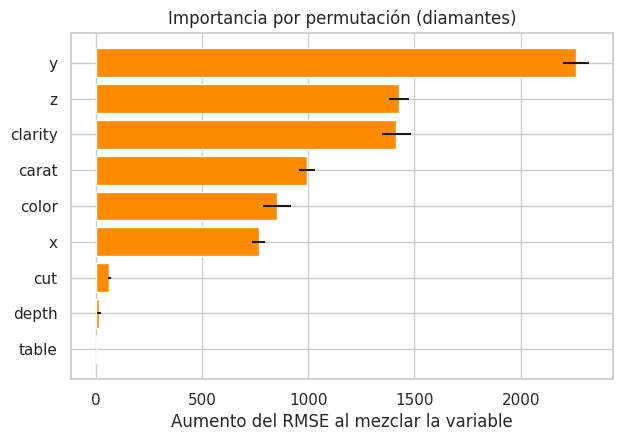

In [ ]:
# 1.6 · Importancia por permutación del mejor modelo

imp_d = permutation_importance(
    mejor_diam, X_prueba_d, y_prueba_d,
    n_repeats=20,                              # repetimos el mezclado 20 veces
    scoring="neg_root_mean_squared_error",
    random_state=SEMILLA
)

importancias_d = pd.DataFrame({
    "variable": X_prueba_d.columns,
    "aumento_RMSE": imp_d.importances_mean,    # cuánto empeora el RMSE al mezclar la variable
    "desvio": imp_d.importances_std
}).sort_values("aumento_RMSE")

display(importancias_d.sort_values("aumento_RMSE", ascending=False))

plt.figure(figsize=(7, 4.5))
plt.barh(importancias_d["variable"], importancias_d["aumento_RMSE"],
         xerr=importancias_d["desvio"], color="darkorange")
plt.xlabel("Aumento del RMSE al mezclar la variable")
plt.title("Importancia por permutación (diamantes)")
plt.show()

**Tu respuesta (1.6):**

Variables más importantes: según la importancia por permutación, las más importantes son y (el RMSE aumenta ≈ 2260 al mezclarla), z (≈ 1427), clarity (≈ 1414), carat (≈ 993), color (≈ 853) y x (≈ 766). Las menos importantes son cut (≈ 63), depth (≈ 14) y table (≈ 0), que casi no aportan al modelo.

En parte coincide con lo esperado. Esperaba que (carat) fuera la variable principal por la relación que vimos en 1.1, pero quedó cuarta. Esto se explica porque x, y, z y carat miden el tamaño del diamante y están muy correlacionadas, por lo que la red reparte la información entre ellas, y en conjunto el tamaño es el factor dominante. También es esperable que (clarity) y (color) sean importantes, ya que aportan información que el tamaño no tiene. Que (cut) casi no importe coincide con lo observado en 1.1, donde los cortes Ideal no tenían los precios más altos. Una limitación a tener en cuenta es que esta importancia describe qué variables usa este modelo, no necesariamente qué determina el precio, y que el orden exacto entre variables correlacionadas no es del todo confiable.

**1.7 · Desafío extra: el precio en escala logarítmica.**

El precio de los diamantes es muy asimétrico (muchos baratos, pocos carísimos). Una técnica habitual es **predecir el logaritmo del precio** y luego volver a la escala original. En `scikit-learn` esto se hace fácil con `TransformedTargetRegressor`:

```python
from sklearn.compose import TransformedTargetRegressor

modelo_log = TransformedTargetRegressor(
    regressor=tu_pipeline_con_mlp,   # el Pipeline que ya armaste
    func=np.log1p,                   # transforma y antes de entrenar
    inverse_func=np.expm1            # revierte la transformación al predecir
)
```

Entrená este modelo, evaluá en prueba y compará con el anterior. ¿Mejoró? ¿Por qué creés que pasa esto?

Épocas realizadas: 94 de un máximo de 2000


,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),4040.451,4249.481,3220.319,-0.001
1,Regresión lineal,1138.336,1106.483,730.659,0.932
2,"MLP inicial (64,32)",587.467,595.227,333.803,0.980
3,MLP optimizado (GridSearch),574.114,589.997,330.885,0.981
4,MLP con log(precio),798.066,909.993,457.254,0.954


Error porcentual medio - MLP optimizado (precio original): 9.4 %
Error porcentual medio - MLP con log(precio): 11.0 %


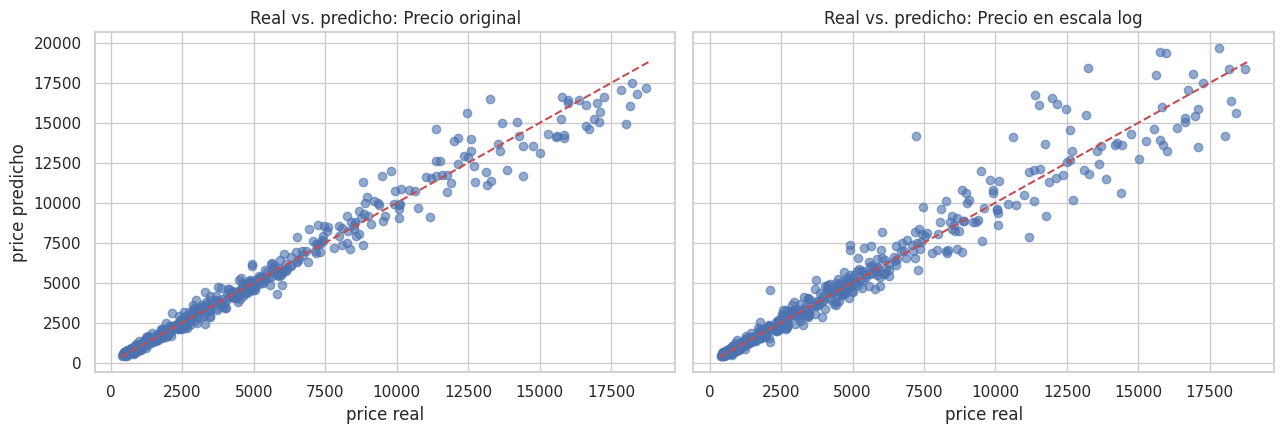

In [ ]:
# 1.7 · Desafío extra: predecir el precio en escala logarítmica
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_percentage_error

# Usamos los mejores hiperparámetros de 1.5 para que la comparación sea justa
modelo_log = TransformedTargetRegressor(
    regressor=clone(mejor_diam),    # mismo Pipeline (prep + MLP), sin entrenar
    func=np.log1p,                  # transforma y antes de entrenar
    inverse_func=np.expm1           # revierte la transformación al predecir
)

modelo_log.fit(X_ent_d, y_ent_d)

# Épocas usadas (el modelo entrenado queda en regressor_)
red_log = modelo_log.regressor_.named_steps["mlp"]
print("Épocas realizadas:", red_log.n_iter_, "de un máximo de", red_log.max_iter)

# Evaluación: las predicciones ya vuelven en dólares
resultados_diam.append(evaluar_regresion(
    modelo_log, X_ent_d, y_ent_d, X_prueba_d, y_prueba_d, "MLP con log(precio)"
))
display(pd.DataFrame(resultados_diam))

# Extra: error porcentual medio (qué tan lejos queda en términos relativos)
for nombre, m in [("MLP optimizado (precio original)", mejor_diam),
                  ("MLP con log(precio)", modelo_log)]:
    mape = mean_absolute_percentage_error(y_prueba_d, m.predict(X_prueba_d))
    print(f"Error porcentual medio - {nombre}: {mape * 100:.1f} %")

# Real vs. predicho de ambos modelos
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
lim = [y_d.min(), y_d.max()]
for eje, m, titulo in [(ejes[0], mejor_diam, "Precio original"),
                       (ejes[1], modelo_log, "Precio en escala log")]:
    eje.scatter(y_prueba_d, m.predict(X_prueba_d), alpha=0.6)
    eje.plot(lim, lim, "r--")
    eje.set_title(f"Real vs. predicho: {titulo}")
    eje.set_xlabel("price real")
ejes[0].set_ylabel("price predicho")
plt.tight_layout()
plt.show()

In [ ]:
# Comprobación: ¿el modelo con log se cortó antes de tiempo?
modelo_log2 = TransformedTargetRegressor(
    regressor=clone(mejor_diam).set_params(mlp__tol=1e-7, mlp__n_iter_no_change=50),
    func=np.log1p,
    inverse_func=np.expm1
)
modelo_log2.fit(X_ent_d, y_ent_d)

red_log2 = modelo_log2.regressor_.named_steps["mlp"]
print("Épocas realizadas:", red_log2.n_iter_, "de un máximo de", red_log2.max_iter)

display(pd.DataFrame([evaluar_regresion(
    modelo_log2, X_ent_d, y_ent_d, X_prueba_d, y_prueba_d, "MLP con log (más épocas)"
)]))
mape2 = mean_absolute_percentage_error(y_prueba_d, modelo_log2.predict(X_prueba_d))
print(f"Error porcentual medio: {mape2 * 100:.1f} %")

Épocas realizadas: 1389 de un máximo de 2000


,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,MLP con log (más épocas),272.573,729.797,372.667,0.97


Error porcentual medio: 9.4 %


**Tu respuesta (1.7):**

¿Mejoró? No. El modelo con precio en escala logarítmica no superó al modelo optimizado entrenado con el precio original. Con la configuración inicial empeoró en todas las métricas: el RMSE en prueba pasó de ≈ 590 a ≈ 910, el MAE de ≈ 331 a ≈ 457, el R² de 0.981 a 0.954 y el error porcentual medio de 9.4 % a 11.0 %. Además, ese modelo se detuvo en solo 94 épocas, frente a las 2000 del anterior.

Comprobación: sospeché que se había cortado antes de tiempo, porque en escala logarítmica los valores y la pérdida son mucho más chicos y el criterio de parada por defecto (tol=1e-4) se alcanza enseguida. Lo verifiqué volviendo a entrenarlo con tol=1e-7 y n_iter_no_change=50. Esta vez usó 1389 épocas y se detuvo por el criterio de parada, no por el límite de 2000. Con ese entrenamiento más completo mejoró bastante (RMSE en prueba ≈ 730, MAE ≈ 373, R² ≈ 0.970 y error porcentual medio 9.4 %), por lo que el mal resultado inicial se debía en buena parte a un entrenamiento incompleto.

Conclusión: aun así, en dólares sigue siendo algo peor que el modelo original (RMSE ≈ 730 contra ≈ 590, R² 0.970 contra 0.981) y en error porcentual medio queda empatado (9.4 % los dos). Además muestra señales de sobreajuste: su RMSE de entrenamiento (≈ 273) es mucho menor que el de prueba (≈ 730), mientras que en el modelo original ambos eran casi iguales (≈ 574 y ≈ 590). En este caso, entonces, transformar el precio con el logaritmo no aportó una mejora sobre el modelo original. Como son resultados de una sola corrida, las diferencias pequeñas no son concluyentes.

---
## Actividad 4 · reflexión final 💭

Respondé brevemente (2-4 líneas cada una) con tus propias palabras:

1. ¿Por qué es **obligatorio** escalar las variables antes de entrenar una red neuronal? ¿Qué observaste en la demostración?
2. ¿Por qué ajustamos hiperparámetros con **validación cruzada sobre el entrenamiento** y no directamente mirando el conjunto de prueba?
3. En el Paso 6 vimos que distintas semillas dan resultados distintos. ¿Cómo influye esto en la forma en que deberíamos **reportar** el rendimiento de una red neuronal?

**Tus respuestas:**

-¿Por qué es obligatorio escalar? Las redes neuronales son muy sensibles a la escala de las variables: si una variable está en miles (como weight, ≈ 3000) y otra entre 3 y 8 (como cylinders), la de mayor magnitud domina el aprendizaje y la red entrena mal. En la demostración, sin escalar el R² en prueba fue muy inestable: −3.391, 0.796, −1.308, 0.891 y −72.231 según la semilla, es decir, negativo (peor que predecir siempre el promedio) en 3 de las 5 corridas, y bueno solo en las otras dos por suerte. Con las variables estandarizadas el R² quedó entre 0.898 y 0.912 en las 5 semillas, con resultados buenos y consistentes.

-¿Por qué validación cruzada sobre el entrenamiento y no mirar el conjunto de prueba? Porque el conjunto de prueba tiene que simular datos nuevos que el modelo nunca vio. Si elegimos los hiperparámetros mirando el resultado en prueba, esa información se filtra en la decisión y la métrica final queda optimista: ya no sería una evaluación honesta. Con la validación cruzada hacemos toda la selección dentro del entrenamiento, promediando varias particiones, y usamos la prueba una sola vez al final. Además, nos permite ver la variabilidad: en la actividad de diamantes, las diferencias entre las mejores combinaciones (RMSE de ≈ 653 a 670) fueron menores que el desvío entre particiones (≈ 55 a 68), así que no eran concluyentes.

-¿Cómo influye la semilla al reportar? Como los pesos iniciales son aleatorios, una sola corrida puede dar un resultado mejor o peor por pura suerte. Al entrenar la misma red con 10 semillas, el R² en prueba varió entre 0.873 y 0.902, con un promedio de 0.887 y un desvío de 0.008. Por eso conviene no reportar un único número, sino el promedio y el desvío (o el rango) de varias semillas o de una validación cruzada, y no sacar conclusiones de diferencias menores a esa variabilidad. También hay que fijar random_state para que los resultados sean reproducibles.

---
# 🏁 ¡Felicitaciones!

Completaste una introducción completa al uso de redes neuronales en `scikit-learn`. Recordá la idea central:

> **Una red neuronal no es magia: es un modelo más que hay que preparar bien, evaluar con honestidad y comparar contra alternativas simples.**

 📚 Para seguir explorando
- Documentación de redes neuronales en scikit-learn: <https://scikit-learn.org/stable/modules/neural_networks_supervised.html>
- Guía de validación cruzada: <https://scikit-learn.org/stable/modules/cross_validation.html>
- Ajuste de hiperparámetros: <https://scikit-learn.org/stable/modules/grid_search.html>
- Importancia por permutación: <https://scikit-learn.org/stable/modules/permutation_importance.html>
- Datasets usados: [Auto MPG (UCI)](https://archive.ics.uci.edu/dataset/9/auto+mpg), [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/), y los datasets de ejemplo de [seaborn-data](https://github.com/mwaskom/seaborn-data).